In [160]:
#imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, KFold, GridSearchCV,cross_validate, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

#Set random seed to the meaning of life
np.random.seed(42)

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [161]:
#Data Download
dataCandidates = [os.path.join("data","insurance.csv"), "insurance.csv"]

csv_path = next((p for p in dataCandidates if os.path.isfile(p)), None)

if csv_path is None:
    try:
        import kagglehub
        dataset_path = kagglehub.dataset_download(
            "willianoliveiragibin/healthcare-insurance"
        )
        csv_path = os.path.join(dataset_path, "insurance.csv")
    except Exception as e:
        raise FileNotFoundError(
            str(e)
        )
df = pd.read_csv(csv_path)
print("Original Shape: ", df.shape)
display(df.head())
display(df.info())

Original Shape:  (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.9000,0,yes,southwest,"16,884.9240"
1,18,male,33.7700,1,no,southeast,"1,725.5523"
2,28,male,33.0000,3,no,southeast,"4,449.4620"
3,33,male,22.7050,0,no,northwest,"21,984.4706"
4,32,male,28.8800,0,no,northwest,"3,866.8552"


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


None

In [162]:
#Check Data Quality and Process
print("Missing vals: ")
display(df.isna().sum())

print("Duplicate rows:", df.duplicated().sum())
print("Summary:")
display(df.describe(include="all").T)

df = df.drop_duplicates().reset_index(drop = True)

requiredCols = ["age", "sex", "bmi", "children", "smoker", "region","charges"]
missingCols = [c for c in requiredCols if c not in df.columns]
if missingCols:
    raise ValueError(f"Missing columns: {missingCols}")

if(df[requiredCols].isnull().values.any()):
    raise ValueError(f"Missing values: {df[requiredCols].isnull().values.any()}")

print("New shape: ", df.shape)
print("Charges Summary: ")
display(df["charges"].describe())

Missing vals: 


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1
Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,"1,338.0000",NaN,NaN,NaN,39.2070,14.0500,18.0000,27.0000,39.0000,51.0000,64.0000
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,"1,338.0000",NaN,NaN,NaN,30.6634,6.0982,15.9600,26.2963,30.4000,34.6938,53.1300
children,"1,338.0000",NaN,NaN,NaN,1.0949,1.2055,0.0000,0.0000,1.0000,2.0000,5.0000
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,"1,338.0000",NaN,NaN,NaN,"13,270.4223","12,110.0112","1,121.8739","4,740.2872","9,382.0330","16,639.9125","63,770.4280"


New shape:  (1337, 7)
Charges Summary: 


count    1,337.0000
mean    13,279.1215
std     12,110.3597
min      1,121.8739
25%      4,746.3440
50%      9,386.1613
75%     16,657.7175
max     63,770.4280
Name: charges, dtype: float64

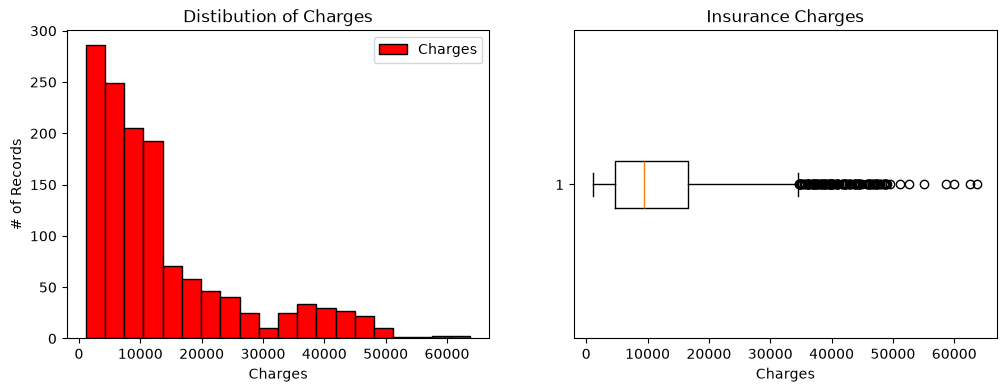

In [163]:
#Distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["charges"], bins=20, edgecolor = "black", color="red", label="Charges")
axes[0].set_xlabel("Charges")
axes[0].set_ylabel("# of Records")
axes[0].legend(loc="upper right")
axes[0].set_title("Distibution of Charges")

axes[1].boxplot(df["charges"], orientation="horizontal")
axes[1].set_xlabel("Charges")
axes[1].set_title("Insurance Charges")
#plt.tight_layout()
plt.show()

In [164]:
#Get the predictors, the target, and assign the 80/20 split so the split is the same across all models.

target = "charges"
numericFeatures = ["age", "bmi", "children"]
categorialFeatures = ["sex", "smoker", "region"]
featureCols = numericFeatures  + categorialFeatures

X = df[featureCols].copy()
Y = df[target].astype(float).copy()

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42)

print("Training Rows: ", len(X_train))
print("Testing Rows: ", len(X_test))
print("Training Frac: ", len(X_train)/len(X))


Training Rows:  1069
Testing Rows:  268
Training Frac:  0.7995512341062079


In [165]:
#Preprocessing and evaluations

def make_preprocessor():
    return ColumnTransformer(
        transformers=[("numeric", StandardScaler(), numericFeatures),("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"), categorialFeatures)
        ],
        remainder="drop"
    )

def regression_evaluations(y_real, y_pred):
    mse = mean_squared_error(y_real, y_pred)
    return{
        "mse": mse,
        "r2": r2_score(y_real, y_pred),
        "mae": mean_absolute_error(y_real, y_pred),
        "rmse": np.sqrt(mean_squared_error(y_real, y_pred)),
    }

def evaluate_predictions(model, y_real, y_pred):
    row = {"Model": model}
    row.update(regression_evaluations(y_real, y_pred))
    return row

def plot_actual_predicted(y_real, y_pred, title):
    low = min(float(np.min(y_real)), float(np.min(y_pred)))
    high = max(float(np.max(y_real)), float(np.max(y_pred)))
    plt.figure(figsize = (10, 10))
    plt.scatter(y_real, y_pred, color = "blue", alpha = 0.5)
    plt.plot([low, high], [low, high], "r--", label = "Perfect Prediction")
    plt.xlabel("Actual chargers ($)")
    plt.ylabel("Predicted chargers ($)")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

def plot_residuals(y_real, y_pred, title):
    resids = np.asarray(y_real) - np.asarray(y_pred)
    plt.figure(figsize = (8, 5))
    plt.scatter(y_pred, resids, color = "blue", alpha = 0.5)
    plt.axhline(0, color="red", linestyle="--")
    plt.xlabel("Predicted charges ($)")
    plt.ylabel("Residual (actual - predicted) ($)")
    plt.title(title)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

In [166]:
#Experiment 1: Linear Regression and Batch Gradient Descent

linearPreprocessor = make_preprocessor()
Xtrain = linearPreprocessor.fit_transform(X_train)
Xtest = linearPreprocessor.transform(X_test)

#Convert to readable matrices for sklearn
Xtrain = Xtrain.toarray() if hasattr(Xtrain, "toarray") else np.asarray(Xtrain)
Xtest = Xtest.toarray() if hasattr(Xtest, "toarray") else np.asarray(Xtest)

#Add an intercept column.
Xtrain_b = np.column_stack([np.ones(Xtrain.shape[0]), Xtrain])
Xtest_b = np.column_stack([np.ones(Xtest.shape[0]), Xtest])

#Standardize Y
YMean = Y_train.mean()
YStd = Y_train.std()
YtrainScaled = (Y_train.to_numpy() - YMean) / YStd

#Least Squares

olsWeights, residuals, rank, singularVals = np.linalg.lstsq(Xtrain_b, YtrainScaled, rcond=None)

def batch_gradient_descent(X, Y, learningRate = 0.01, iterations = 10000):
    m,n = X.shape
    weights = np.zeros(n)
    costs = []

    for _ in range(iterations):
        errors = X @ weights - Y
        gradient = (X.T @ errors) / m
        weights -= learningRate * gradient

        updatedErrors = X @ weights - Y
        cost = np.sum(updatedErrors ** 2) / (2*m)
        costs.append(cost)

    return weights, costs

gradientWeights, gradientCosts = batch_gradient_descent(Xtrain_b, YtrainScaled)

print("Max coefficient difference (ordinary least squares vs gradient descent): ", np.max(np.abs(olsWeights - gradientWeights)))
print("Final GD cost: ", gradientCosts[-1])

Max coefficient difference (ordinary least squares vs gradient descent):  0.0006165299030811006
Final GD cost:  0.13492081263652805


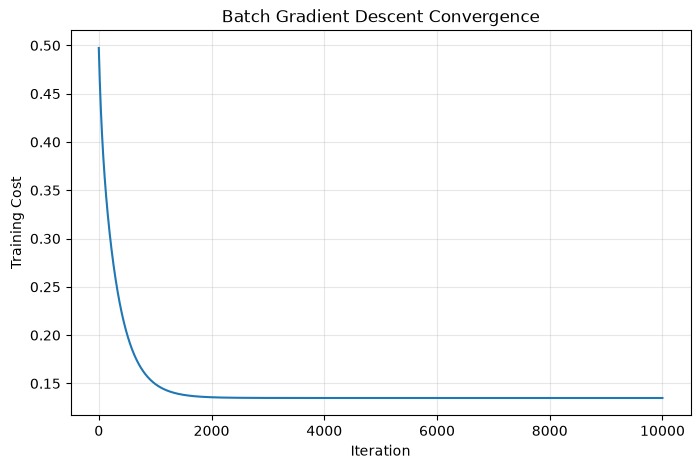

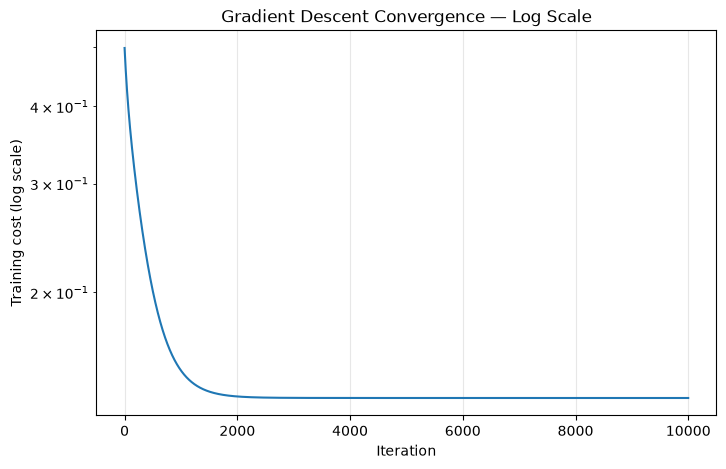

In [167]:
#Visualizations

plt.figure(figsize = (8,5))
plt.plot(gradientCosts)
plt.xlabel("Iteration")
plt.ylabel("Training Cost")
plt.title("Batch Gradient Descent Convergence")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8, 5))
plt.semilogy(gradientCosts)
plt.xlabel("Iteration")
plt.ylabel("Training cost (log scale)")
plt.title("Gradient Descent Convergence — Log Scale")
plt.grid(alpha=0.3)
plt.show()

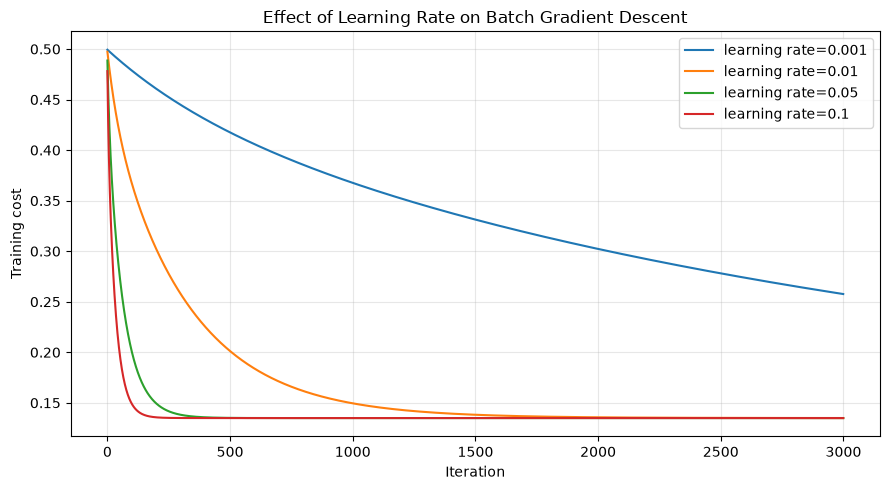

In [168]:
#Learning Rate/Iteration Count Effects & Visualization

learningRates = [0.001, 0.01, 0.05, 0.1]
plt.figure(figsize=(9, 5))

for lr in learningRates:
    _, costs = batch_gradient_descent(Xtrain_b, YtrainScaled, learningRate=lr, iterations=3000)
    plt.plot(costs, label=f"learning rate={lr}")

plt.xlabel("Iteration")
plt.ylabel("Training cost")
plt.title("Effect of Learning Rate on Batch Gradient Descent")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,Model,mse,r2,mae,rmse
0,Least Squares,"35,478,020.6752",0.8069,"4,177.0456","5,956.3429"
1,Gradient Descent,"35,476,333.7537",0.8069,"4,177.1237","5,956.2013"


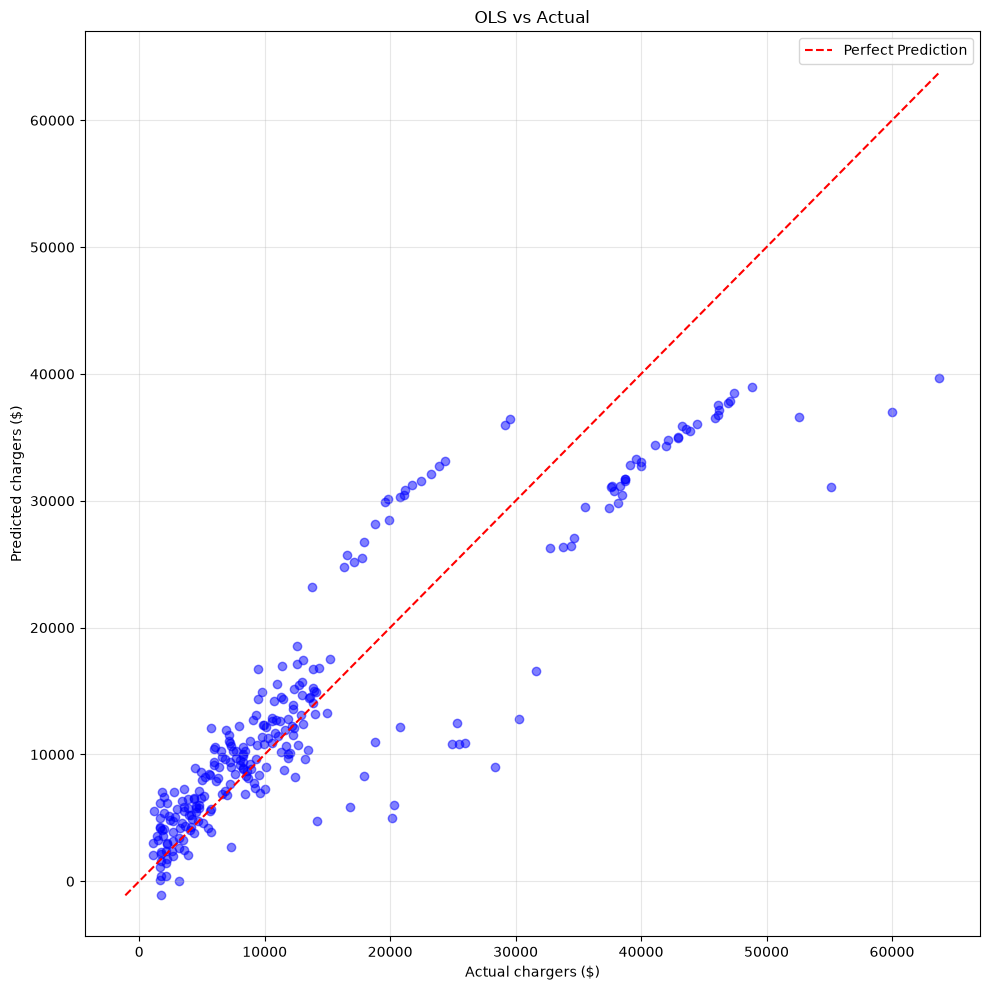

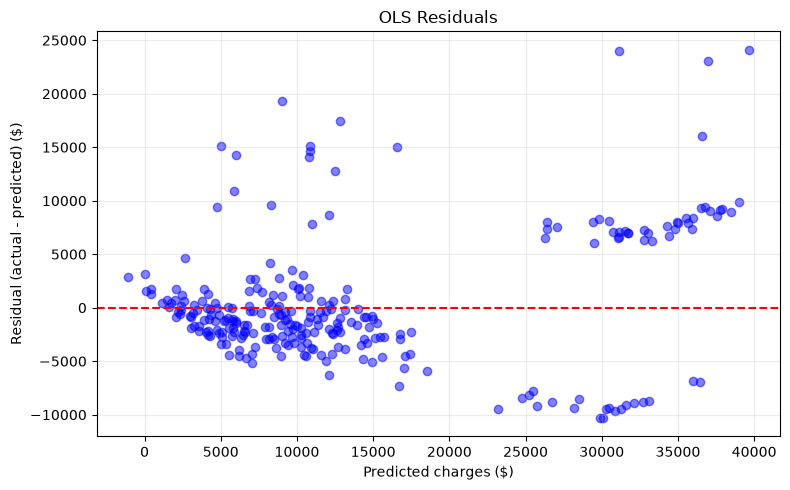

In [169]:
#OLS vs Gradient Descent on Test Set

def predictTarget(X, weights):
    prediction = X @ weights
    return prediction * YStd + YMean

OLSPrediction = predictTarget(Xtest_b, olsWeights)
gradientPrediction = predictTarget(Xtest_b, gradientWeights)

experimentOneResults = pd.DataFrame([evaluate_predictions("Least Squares", Y_test, OLSPrediction),
evaluate_predictions("Gradient Descent", Y_test, gradientPrediction)])
display(experimentOneResults)

plot_actual_predicted(Y_test, OLSPrediction, "OLS vs Actual")
plot_residuals(Y_test, OLSPrediction, "OLS Residuals")

In [170]:
#Ridge regression | Experiment 2

def ridge_gradient_descent(X, Y, alpha, learning_rate = 0.01, iterations = 10000):
    m,n = X.shape
    weights = np.zeros(n)
    costs = []

    for _ in range(iterations):
        errors = X @ weights - Y
        gradient = (X.T @ errors) / m
        gradient[1:] += (alpha/m) * weights[1:]
        weights -= learning_rate * gradient
        updatedErrors = X @ weights - Y
        cost = np.sum(updatedErrors ** 2) / (2*m)
        cost += (alpha / (2*m)) * np.sum(weights[1:] ** 2)
        costs.append(cost)

    return weights, costs

ridgeAlphas = [0.1, 1, 10, 100, 1000, 5000, 10000]
ridgeModels = {}
ridgeRows = []
ridgePredictions = {}

for alpha in ridgeAlphas:
    w, costs = ridge_gradient_descent(Xtrain_b, YtrainScaled, alpha=alpha)
    prediction = predictTarget(Xtest_b, w)
    ridgeModels[alpha] = {"weights": w, "costs": costs}
    ridgePredictions[alpha] = prediction
    row = evaluate_predictions(f"Ridge alpha of {alpha}: ", Y_test, prediction)
    row["alpha"] = alpha
    ridgeRows.append(row)

ridgeResults_df = pd.DataFrame(ridgeRows)
display(ridgeResults_df)

,Model,mse,r2,mae,rmse,alpha
0,Ridge alpha of 0.1:,"35,494,649.5309",0.8068,"4,178.8173","5,957.7386",0.1000
1,Ridge alpha of 1:,"35,661,550.9673",0.8059,"4,193.9673","5,971.7293",1.0000
2,Ridge alpha of 10:,"37,506,694.3780",0.7959,"4,344.1954","6,124.2709",10.0000
3,Ridge alpha of 100:,"60,358,512.0448",0.6715,"5,521.8415","7,769.0741",100.0000
4,Ridge alpha of 1000:,"137,359,111.1257",0.2525,"8,640.2956","11,720.0303","1,000.0000"
5,Ridge alpha of 5000:,"170,679,707.8545",0.0712,"9,523.9507","13,064.4444","5,000.0000"
6,Ridge alpha of 10000:,"177,355,980.5873",0.0348,"9,677.9507","13,317.5065","10,000.0000"


,Feature,Linear,Ridge alpha=0.1,Ridge alpha=1,Ridge alpha=10,Ridge alpha=100,Ridge alpha=1000,Ridge alpha=5000,Ridge alpha=10000
0,Intercept,-0.3487,-0.3481,-0.3469,-0.3357,-0.2467,-0.0663,-0.0157,-0.0080
1,numeric__age,0.2967,0.2966,0.2963,0.2928,0.2644,0.1458,0.0504,0.0278
2,numeric__bmi,0.1647,0.1647,0.1643,0.1610,0.1405,0.0823,0.0302,0.0169
3,numeric__children,0.0544,0.0544,0.0544,0.0550,0.0569,0.0392,0.0146,0.0081
4,categorical__sex_male,-0.0087,-0.0087,-0.0079,-0.0011,0.0298,0.0217,0.0059,0.0031
5,categorical__smoker_yes,1.9714,1.9701,1.9596,1.8603,1.2358,0.2843,0.0641,0.0326
6,categorical__region_northwest,-0.0335,-0.0340,-0.0338,-0.0320,-0.0297,-0.0152,-0.0044,-0.0024
7,categorical__region_southeast,-0.0717,-0.0721,-0.0706,-0.0573,0.0005,0.0188,0.0063,0.0034
8,categorical__region_southwest,-0.0563,-0.0569,-0.0563,-0.0519,-0.0357,-0.0122,-0.0031,-0.0016


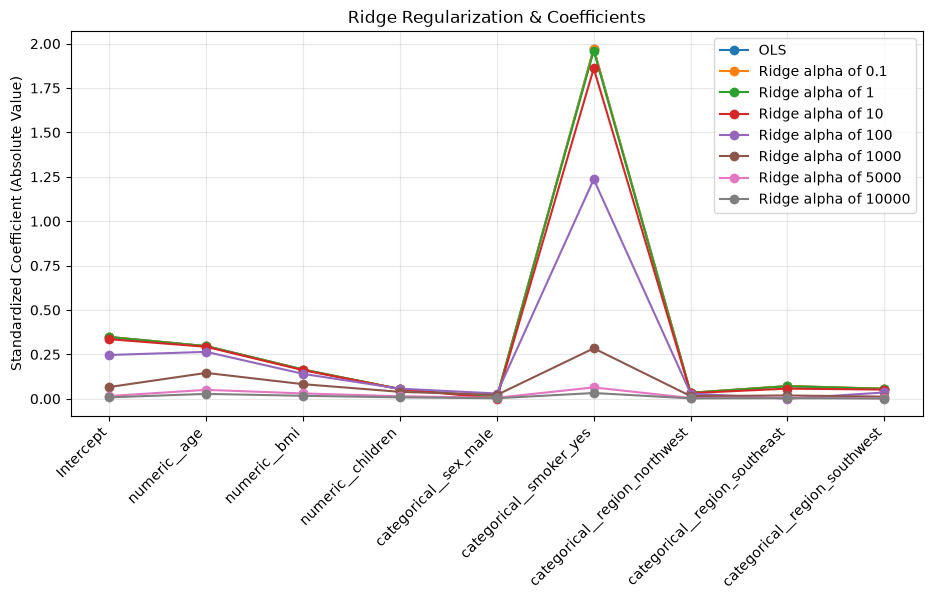

In [171]:
#Examine what a higher ridge alpha makes weight coefficients
featureNames = ["Intercept"] + list(linearPreprocessor.get_feature_names_out())

coef_table = pd.DataFrame({"Feature": featureNames, "Linear": olsWeights})
for alpha, model in ridgeModels.items():
    coef_table[f"Ridge alpha={alpha}"] = model["weights"]

display(coef_table)

plt.figure(figsize=(11,5))
XPos = np.arange(len(featureNames))
plt.plot(XPos, np.abs(olsWeights), marker="o", label="OLS")
for alpha in ridgeAlphas:
    plt.plot(XPos, np.abs(ridgeModels[alpha]["weights"]), marker="o", label=f"Ridge alpha of {alpha}")
plt.xticks(XPos, featureNames, rotation = 45, ha = "right")
plt.ylabel("Standardized Coefficient (Absolute Value)")
plt.title("Ridge Regularization & Coefficients")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [172]:
#Determine best ridge alpha using Scikit learn and test predictions

#I based this off https://medium.com/geekculture/regularization-using-pipeline-gridsearchcv-f377946e39d1

ridgePipeline = Pipeline([
    ("preprocess", make_preprocessor()),
    ("scale", StandardScaler()),
    ("ridge", Ridge())
])

ridgeSearch = GridSearchCV(
    ridgePipeline,
    param_grid={"ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000, 5000]},
    scoring="neg_root_mean_squared_error",
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1
)

ridgeSearch.fit(X_train, Y_train)
bestRidgePred = ridgeSearch.predict(X_test)
print("Best Ridge Alpha: ", ridgeSearch.best_params_["ridge__alpha"])
print("Best RMSE:", -ridgeSearch.best_score_)
display(pd.DataFrame([evaluate_predictions("Cross Validated Ridge", Y_test,bestRidgePred)]))
plot_actual_predicted(Y_test, bestRidgePred, "Cross Validated (Skikit) Ridge")
plot_residuals(Y_test, bestRidgePred, "Cross Validated Ridge Residuals")

KeyboardInterrupt: 

In [ ]:
#Polynomial Regression | Experiment 3 this took way too long
def polynomial_preprocessor(degree):
    #Based on same pipeline from above. Uses scikit learn again
    numericPipeline = Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scale", StandardScaler())
    ])
    return ColumnTransformer([
        ("numeric_poly", numericPipeline, numericFeatures),
        ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"),
         categorialFeatures)
    ])

degrees = [1, 2, 3, 4]
polynomialModels = {}
polynomialRows = []

for degree in degrees:
    pipeline = Pipeline([
        ("preprocess", polynomial_preprocessor(degree)),
        ("scale_all", StandardScaler()),
        ("regression", LinearRegression())
    ])
    pipeline.fit(X_train, Y_train)
    trainPrediction = pipeline.predict(X_train)
    testPrediction = pipeline.predict(X_test)
    trainMetrics = regression_evaluations(Y_train, trainPrediction)
    testMetrics = regression_evaluations(Y_test, testPrediction)

    polynomialModels[degree] = pipeline
    polynomialRows.append({
        "Degree": degree,
        "Train RMSE": trainMetrics["rmse"],
        "Test RMSE": testMetrics["rmse"],
        "Train R2": trainMetrics["r2"],
        "Test R2": testMetrics["r2"],
        "Test MAE": testMetrics["mae"]
    })

polynomialResults_df = pd.DataFrame(polynomialRows)
display(polynomialResults_df)

In [ ]:
#Create visuals
plt.figure(figsize=(11,5))
plt.plot(polynomialResults_df["Degree"], polynomialResults_df["Train RMSE"], marker="o", label="Train RMSE")
plt.plot(polynomialResults_df["Degree"], polynomialResults_df["Test RMSE"], marker="o", label="Test RMSE")
plt.xlabel("Degree")
plt.ylabel("RMSE")
plt.title("Polynomial Degree vs Error")
plt.xticks(degrees)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(11,5))
plt.plot(polynomialResults_df["Degree"], polynomialResults_df["Train R2"], marker="o", label="Train R2")
plt.plot(polynomialResults_df["Degree"], polynomialResults_df["Test R2"], marker="o", label="Test R2")
plt.xlabel("Degree")
plt.ylabel("R^2")
plt.title("Polynomial Degree vs R^2")
plt.xticks(degrees)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
#Visuals for test predictions for each degree
for degree in degrees:
    prediction = polynomialModels[degree].predict(X_test)
    plot_actual_predicted(Y_test, prediction, f"Polynomial degree: {degree}")


In [ ]:
for degree in degrees:
    prediction = polynomialModels[degree].predict(X_test)
    plot_residuals(Y_test, prediction, f"Residual | Polynomial Degree: {degree}")

In [ ]:
#Ridge/L2 regularized Polynomial Regression using scikit learn | Experiment 4
#This is here to just test whether or not
#A ridge regularized model can actualy handle large coefficients.
#The gridsearch idea was taken from https://www.geeksforgeeks.org/machine-learning/performing-feature-selection-with-gridsearchcv-in-sklearn/ once again
#This essentially combines experiment 2 and 3
#Gridsearch selects an alpha using the KFold then evaluates the pipeline.
#A KFold is just another method to test how well a model performs https://www.geeksforgeeks.org/machine-learning/k-fold-cross-validation-in-machine-learning/

ridgePolynomialRows = []
ridgePolynomialModels = {}
ridgePolynomialPredictions = {}

alphas = [0.01, 0.1, 1, 10, 100, 1000]
crossValidation = KFold(n_splits=5, shuffle=True, random_state=42)

for degree in degrees:
    pipeline = Pipeline([
        ("preprocess", polynomial_preprocessor(degree)),
        ("scale_all", StandardScaler()),
        ("ridge", Ridge())
    ])

    search = GridSearchCV(
        pipeline,
        param_grid = {"ridge__alpha": alphas},
        scoring =  "neg_mean_squared_error",
        cv = crossValidation,
        n_jobs = -1
    )
    #Deja Vu?
    search.fit(X_train, Y_train)
    trainPrediction = search.predict(X_train)
    testPrediction = search.predict(X_test)
    trainMetrics = regression_evaluations(Y_train, trainPrediction)
    testMetrics = regression_evaluations(Y_test, testPrediction)

    ridgePolynomialModels[degree] = search
    ridgePolynomialPredictions[degree] = testPrediction

    ridgePolynomialRows.append({
        "Degree": degree,
        "Optimal Alpha": search.best_params_["ridge__alpha"],
        "Mean RMSE for CV": -search.best_score_,
        "Train RMSE": trainMetrics["rmse"],
        "Test RMSE": testMetrics["rmse"],
        "Train R2": trainMetrics["r2"],
        "Test R2": testMetrics["r2"],
        "Test MAE": testMetrics["mae"]
    })

ridgePolyResults_df = pd.DataFrame(ridgePolynomialRows)
display(ridgePolyResults_df)

In [ ]:
#Compare the polynomial regression to it with or without the ridge regression
#ref: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html
polynomialComparison = polynomialResults_df.merge(
    ridgePolyResults_df[["Degree", "Optimal Alpha", "Train RMSE", "Test RMSE"]],
    on="Degree",
    suffixes=("_Polynomial", "_RidgePolynomial")
)
display(polynomialComparison)

plt.figure(figsize = (11,5))
plt.plot(polynomialComparison["Degree"], polynomialComparison["Test RMSE_Polynomial"], marker="o", label="Polynomial without Ridge")
plt.plot(polynomialComparison["Degree"], polynomialComparison["Test RMSE_RidgePolynomial"], marker="o", label="Polynomial with Ridge")
plt.xlabel("Degree")
plt.ylabel("RMSE")
plt.title("Polynomial With vs Without Ridge")
plt.xticks(degrees)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(11, 5))
plt.plot(polynomialComparison["Degree"],polynomialComparison["Train RMSE_Polynomial"], marker="o",label="Polynomial training RMSE")
plt.plot(polynomialComparison["Degree"],polynomialComparison["Test RMSE_Polynomial"], marker="o",label="Polynomial test RMSE")
plt.plot(polynomialComparison["Degree"],polynomialComparison["Train RMSE_RidgePolynomial"], marker="o",label="Ridge-polynomial training RMSE")
plt.plot(polynomialComparison["Degree"],polynomialComparison["Test RMSE_RidgePolynomial"], marker="o",label="Ridge-polynomial test RMSE")
plt.xlabel("Polynomial degree")
plt.ylabel("RMSE ($)")
plt.title("Training vs Test Error: Polynomial and Ridge-Polynomial")
plt.xticks(degrees)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
#Final comparison of all models.

finalRows = []

finalRows.append(evaluate_predictions("OLS analytical", Y_test, OLSPrediction))
finalRows.append(evaluate_predictions("Batch gradient descent", Y_test, gradientPrediction))
finalRows.append(evaluate_predictions("Ridge (CV-selected)", Y_test, bestRidgePred))

for degree in degrees:
    prediction = polynomialModels[degree].predict(X_test)
    finalRows.append(evaluate_predictions(f"Polynomial degree {degree}", Y_test, prediction))

for degree in degrees:
    prediction = ridgePolynomialPredictions[degree]
    alpha = ridgePolynomialModels[degree].best_params_["ridge__alpha"]
    finalRows.append(evaluate_predictions(
        f"Polynomial degree {degree} + Ridge alpha {alpha}", Y_test, prediction
    ))

finalResults_df = pd.DataFrame(finalRows).sort_values("rmse")
display(finalResults_df)

os.makedirs("results", exist_ok=True)
finalResults_df.to_csv("results/final_model_comparison.csv", index=False)
ridgeResults_df.to_csv("results/ridge_alpha_comparison.csv", index=False)
polynomialResults_df.to_csv("results/polynomial_degree_comparison.csv", index=False)
ridgePolyResults_df.to_csv("results/ridge_polynomial_comparison.csv", index=False)

In [ ]:

# Experiment 5: Determining Input Importance

from sklearn.model_selection import cross_val_score

# The best-performing model so far is ordinary linear regression.
# Use a pipeline so preprocessing is fitted independently in each CV fold.

def make_feature_pipeline(features):
    numeric = [f for f in features if f in numericFeatures]
    categorical = [f for f in features if f in categorialFeatures]

    transformers = []

    if numeric:
        transformers.append(
            ("numeric", StandardScaler(), numeric)
        )

    if categorical:
        transformers.append(
            ("categorical",
             OneHotEncoder(drop="first", handle_unknown="ignore"),
             categorical)
        )

    return Pipeline([
        ("preprocess", ColumnTransformer(transformers)),
        ("regression", LinearRegression())
    ])


# All six predictors
allFeatures = numericFeatures + categorialFeatures

# Individual feature removal experiments
featurePermutations = {
    "All 6 predictors": allFeatures,
    "Without Region": [f for f in allFeatures if f != "region"],
    "Without BMI": [f for f in allFeatures if f != "bmi"],
    "Without Smoker": [f for f in allFeatures if f != "smoker"],
    "Without Sex": [f for f in allFeatures if f != "sex"]
}

# Evaluate every permutation using cross-validation on training data.
cv = KFold(n_splits=5, shuffle=True, random_state=42)

featureRows = []
featureModels = {}

for name, features in featurePermutations.items():

    model = make_feature_pipeline(features)

    cvScores = cross_val_score(
        model,
        X_train[features],
        Y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    model.fit(X_train[features], Y_train)

    testPrediction = model.predict(X_test[features])

    metrics = regression_evaluations(Y_test, testPrediction)

    featureModels[name] = model

    featureRows.append({
        "Permutation": name,
        "Features": features,
        "Cross Validated RMSE": -cvScores.mean(),
        "Test RMSE": metrics["rmse"],
        "Test MAE": metrics["mae"],
        "Test R2": metrics["r2"]
    })


featureResults_df = pd.DataFrame(featureRows)

display(
    featureResults_df.sort_values("Cross Validated RMSE")
)

# Identify individually beneficial removals using CV results.
baselineCV = featureResults_df.loc[
    featureResults_df["Permutation"] == "All 6 predictors",
    "Cross Validated RMSE"
].iloc[0]

improvedRemovals = []

for _, row in featureResults_df.iterrows():
    if row["Permutation"] == "All 6 predictors":
        continue

    if row["Cross Validated RMSE"] < baselineCV:
        removedFeature = row["Permutation"].replace("Without ", "").lower()
        improvedRemovals.append(removedFeature)

print("Individual removals that improved Cross Validated RMSE:")
print(improvedRemovals)

# Test a combination of all individually beneficial removals.
if len(improvedRemovals) >= 2:

    combinedFeatures = [
        f for f in allFeatures if f not in improvedRemovals
    ]

    combinedModel = make_feature_pipeline(combinedFeatures)

    combinedScores = cross_val_score(
        combinedModel,
        X_train[combinedFeatures],
        Y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    combinedModel.fit(
        X_train[combinedFeatures],
        Y_train
    )

    combinedPrediction = combinedModel.predict(
        X_test[combinedFeatures]
    )

    combinedMetrics = regression_evaluations(
        Y_test,
        combinedPrediction
    )

    featureModels["Combined removals"] = combinedModel

    combinedRow = {
        "Permutation": "Combined removals",
        "Features": combinedFeatures,
        "Cross Validated RMSE": -combinedScores.mean(),
        "Test RMSE": combinedMetrics["rmse"],
        "Test MAE": combinedMetrics["mae"],
        "Test R2": combinedMetrics["r2"]
    }

    featureResults_df = pd.concat(
        [featureResults_df, pd.DataFrame([combinedRow])],
        ignore_index=True
    )

display(featureResults_df.sort_values("Cross Validated RMSE"))

# Visual comparison
plt.figure(figsize=(11, 5))

plt.bar(
    featureResults_df["Permutation"],
    featureResults_df["Cross Validated RMSE"]
)

plt.ylabel("Cross-Validation RMSE ($)")
plt.xlabel("Feature Permutation")
plt.title("Effect of Removing Input Features")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Save results
featureResults_df.to_csv(
    "results/feature_importance_comparison.csv",
    index=False
)


,Permutation,Features,Cross Validated RMSE,Test RMSE,Test MAE,Test R2
1,Without Region,"[age, bmi, children, sex, smoker]","6,113.8494","5,991.8206","4,198.1118",0.8046
4,Without Gender,"[age, bmi, children, smoker, region]","6,121.9952","5,957.5299","4,177.6533",0.8069
0,All 6 predictors,"[age, bmi, children, sex, smoker, region]","6,123.6513","5,956.3429","4,177.0456",0.8069
5,Without Children,"[age, bmi, sex, smoker, region]","6,151.1877","5,952.1475","4,175.9108",0.8072
2,Without BMI,"[age, children, sex, smoker, region]","6,393.5318","6,442.5874","4,135.0602",0.7741
6,Without Age,"[bmi, children, sex, smoker, region]","7,036.2243","7,232.4314","5,585.6889",0.7153
3,Without Smoker,"[age, bmi, children, sex, region]","11,070.0393","12,608.4452","9,546.1805",0.1349


Individual removals that improved Cross Validated RMSE:
['region', 'gender']


,Permutation,Features,Cross Validated RMSE,Test RMSE,Test MAE,Test R2
1,Without Region,"[age, bmi, children, sex, smoker]","6,113.8494","5,991.8206","4,198.1118",0.8046
7,Combined removals,"[age, bmi, children, sex, smoker]","6,113.8494","5,991.8206","4,198.1118",0.8046
4,Without Gender,"[age, bmi, children, smoker, region]","6,121.9952","5,957.5299","4,177.6533",0.8069
0,All 6 predictors,"[age, bmi, children, sex, smoker, region]","6,123.6513","5,956.3429","4,177.0456",0.8069
5,Without Children,"[age, bmi, sex, smoker, region]","6,151.1877","5,952.1475","4,175.9108",0.8072
2,Without BMI,"[age, children, sex, smoker, region]","6,393.5318","6,442.5874","4,135.0602",0.7741
6,Without Age,"[bmi, children, sex, smoker, region]","7,036.2243","7,232.4314","5,585.6889",0.7153
3,Without Smoker,"[age, bmi, children, sex, region]","11,070.0393","12,608.4452","9,546.1805",0.1349


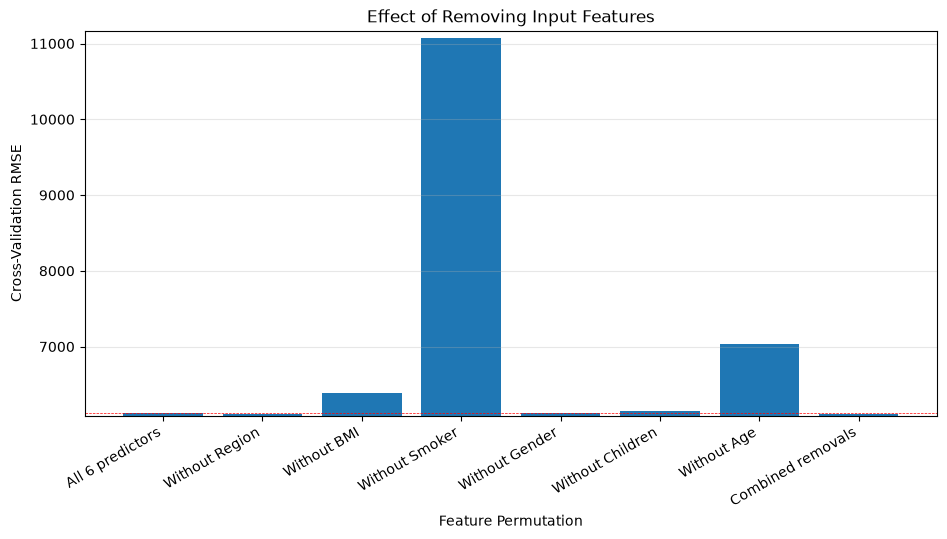

In [179]:

#Experiment 5: Determining Input Importance

#The best-performing model so far is ordinary linear regression so that is what we will test input on
#We will use cross validation to check error and if the cross validated error improves then we will say that the model performed better without that feature.

def make_feature_pipeline(features):
    numeric = [f for f in features if f in numericFeatures]
    categorical = [f for f in features if f in categorialFeatures]

    transformers = []

    if numeric: transformers.append(("numeric", StandardScaler(), numeric))
    if categorical: transformers.append(("categorical",OneHotEncoder(drop="first", handle_unknown="ignore"),categorical))

    return Pipeline([
        ("preprocess", ColumnTransformer(transformers)),
        ("regression", LinearRegression())
    ])


allFeatures = numericFeatures + categorialFeatures

#Individual removal experiments
featurePermutations = {
    "All 6 predictors": allFeatures,
    "Without Region": [f for f in allFeatures if f != "region"],
    "Without BMI": [f for f in allFeatures if f != "bmi"],
    "Without Smoker": [f for f in allFeatures if f != "smoker"],
    "Without Gender": [f for f in allFeatures if f != "sex"],
    "Without Children": [f for f in allFeatures if f != "children"],
    "Without Age": [f for f in allFeatures if f != "age"]
}

crossValidation = KFold(n_splits=5, shuffle=True, random_state=42)

featureRows = []
featureModels = {}

for name, features in featurePermutations.items():
    model = make_feature_pipeline(features)
    cvScores = cross_val_score(
        model,
        X_train[features],
        Y_train,
        cv=crossValidation,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )
    model.fit(X_train[features], Y_train)
    testPrediction = model.predict(X_test[features])
    metrics = regression_evaluations(Y_test, testPrediction)
    featureModels[name] = model
    featureRows.append({
        "Permutation": name,
        "Features": features,
        "Cross Validated RMSE": -cvScores.mean(),
        "Test RMSE": metrics["rmse"],
        "Test MAE": metrics["mae"],
        "Test R2": metrics["r2"]
    })

featureResults_df = pd.DataFrame(featureRows)

display(featureResults_df.sort_values("Cross Validated RMSE"))
#Identify individual removals using CV results. This essentually does the permutations for us
baselineCV = featureResults_df.loc[featureResults_df["Permutation"] == "All 6 predictors","Cross Validated RMSE"].iloc[0]

improvedRemovals = []

for _, row in featureResults_df.iterrows():
    if row["Permutation"] == "All 6 predictors":
        continue

    if row["Cross Validated RMSE"] < baselineCV:
        removedFeature = row["Permutation"].replace("Without ", "").lower()
        improvedRemovals.append(removedFeature)

print("Individual removals that improved Cross Validated RMSE:")
print(improvedRemovals)

#Test a combination of all individually beneficial removals.
if len(improvedRemovals) >= 2:

    combinedFeatures = [f for f in allFeatures if f not in improvedRemovals]
    combinedModel = make_feature_pipeline(combinedFeatures)
    combinedScores = cross_val_score(combinedModel,X_train[combinedFeatures],Y_train,cv=crossValidation,scoring="neg_root_mean_squared_error",n_jobs=-1)
    combinedModel.fit(X_train[combinedFeatures],Y_train)

    combinedPrediction = combinedModel.predict(X_test[combinedFeatures])

    combinedMetrics = regression_evaluations(Y_test,combinedPrediction)

    featureModels["Combined removals"] = combinedModel

    combinedRow = {"Permutation": "Combined removals","Features": combinedFeatures,"Cross Validated RMSE": -combinedScores.mean(),"Test RMSE": combinedMetrics["rmse"],"Test MAE": combinedMetrics["mae"],"Test R2": combinedMetrics["r2"]}

    featureResults_df = pd.concat([featureResults_df, pd.DataFrame([combinedRow])],ignore_index=True)

display(featureResults_df.sort_values("Cross Validated RMSE"))

plt.figure(figsize=(11, 5))

plt.bar(featureResults_df["Permutation"],featureResults_df["Cross Validated RMSE"])

plt.ylabel("Cross-Validation RMSE")
plt.xlabel("Feature Permutation")
plt.title("Effect of Removing Input Features")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
baselineCV = featureResults_df.loc[featureResults_df["Permutation"] == "All 6 predictors","Cross Validated RMSE"].iloc[0]
plt.axhline(y=baselineCV,color = "red", linestyle="--",linewidth=.5,label=f"All 6 Predictors: {baselineCV:,.2f}")
lowestCrossVal = featureResults_df["Cross Validated RMSE"].min()
plt.ylim(lowestCrossVal - 25,featureResults_df["Cross Validated RMSE"].max() + 100)
plt.show()

featureResults_df.to_csv("results/feature_comparison.csv",index=False)
